# Portfolio-analyse & optimalisatie 3
We gaan kijken of we onze portfolio kunnen optimaliseren. Daarvoor lezen we eerst weer de benodigde libraries in:

In [1]:
! pip install pandas-datareader==0.10.0
! pip install yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import numpy as np
import scipy.stats as scs
import statsmodels.api as sm
import matplotlib.pyplot as plt
import datetime as dt

from datetime import date

#Clear output
from google.colab import output
output.clear()

En vervolgens onze portfolio:

In [2]:
yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2023,5,1)

In [3]:
inflatie = web.get_data_fred('T10YIE', start, end) #inflatie
rente = web.get_data_fred('FEDFUNDS', start, end) #rente

graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = web.get_data_yahoo('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = web.get_data_yahoo('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = web.get_data_yahoo('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = web.get_data_yahoo('SI=F', start, end).tz_localize(None) #zilver future

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


In [24]:
indicatoren = pd.concat([graan, koffie, vlees, gas, kolen, oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis=1)
indicatoren_gefilterd = indicatoren.loc[:, ["PWHEAMTUSDM", "WPU026301","PBEEFUSDM","WPU058103","Close_Olie","Close_Goud","Close_Palladium"]]
indicatoren_gevuld = indicatoren_gefilterd.ffill()
indicatoren_gevuld

,PWHEAMTUSDM,WPU026301,PBEEFUSDM,WPU058103,Close_Olie,Close_Goud,Close_Palladium
2018-05-01,192.703830,194.200,188.000,595.400,67.250000,1303.800049,938.450012
2018-05-02,192.703830,194.200,188.000,595.400,67.930000,1302.599976,962.349976
2018-05-03,192.703830,194.200,188.000,595.400,68.430000,1310.699951,960.900024
2018-05-04,192.703830,194.200,188.000,595.400,69.720001,1312.699951,959.450012
2018-05-07,192.703830,194.200,188.000,595.400,70.730003,1312.199951,964.299988
...,...,...,...,...,...,...,...
2023-04-25,312.810824,244.323,248.375,904.404,77.070000,1994.000000,1477.599976
2023-04-26,312.810824,244.323,248.375,904.404,74.300003,1985.699951,1505.099976
2023-04-27,312.810824,244.323,248.375,904.404,74.760002,1989.900024,1500.400024
2023-04-28,312.810824,244.323,248.375,904.404,76.779999,1990.099976,1517.900024


Onze (voorbeeld)portfolio bestaat uit 7 onderdelen:<br>
- Graan
- Koffiebonen
- Vlees
- Kolen
- Olie
- Goud
- Palladium

In [25]:
indicatoren_gevuld.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1305 entries, 2018-05-01 to 2023-05-01
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PWHEAMTUSDM      1305 non-null   float64
 1   WPU026301        1305 non-null   float64
 2   PBEEFUSDM        1305 non-null   float64
 3   WPU058103        1305 non-null   float64
 4   Close_Olie       1305 non-null   float64
 5   Close_Goud       1305 non-null   float64
 6   Close_Palladium  1305 non-null   float64
dtypes: float64(7)
memory usage: 81.6 KB


In [26]:
indicatoren_gevuld.tail()

,PWHEAMTUSDM,WPU026301,PBEEFUSDM,WPU058103,Close_Olie,Close_Goud,Close_Palladium
2023-04-25,312.810824,244.323,248.375,904.404,77.070000,1994.000000,1477.599976
2023-04-26,312.810824,244.323,248.375,904.404,74.300003,1985.699951,1505.099976
2023-04-27,312.810824,244.323,248.375,904.404,74.760002,1989.900024,1500.400024
2023-04-28,312.810824,244.323,248.375,904.404,76.779999,1990.099976,1517.900024
2023-05-01,312.810824,244.323,248.375,904.404,76.779999,1990.099976,1517.900024


<Axes: >

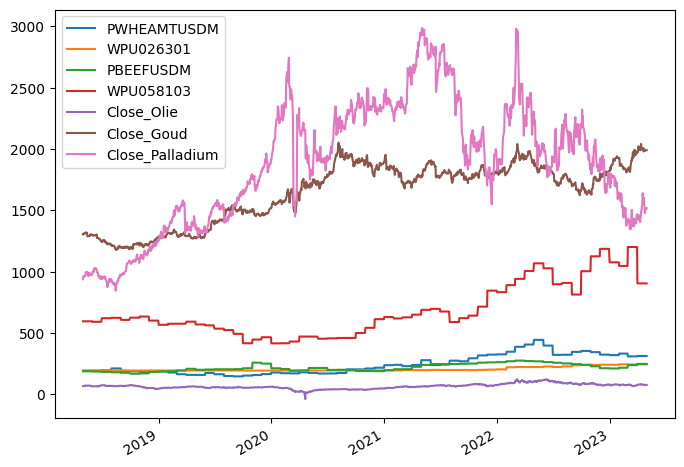

In [27]:
indicatoren_gevuld.plot(figsize=(8,6))

Daarna zetten we de dagkoersen om in dagrendementen:

In [28]:
log_returns_na = np.log(indicatoren_gevuld / indicatoren_gevuld.shift(1))
log_returns = log_returns_na.dropna()
log_returns.head()

/usr/local/lib/python3.10/dist-packages/pandas/core/internals/blocks.py:351: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


,PWHEAMTUSDM,WPU026301,PBEEFUSDM,WPU058103,Close_Olie,Close_Goud,Close_Palladium
2018-05-02,0.0,0.0,0.0,0.0,0.010061,-0.000921,0.025149
2018-05-03,0.0,0.0,0.0,0.0,0.007334,0.006199,-0.001508
2018-05-04,0.0,0.0,0.0,0.0,0.018676,0.001525,-0.001510
2018-05-07,0.0,0.0,0.0,0.0,0.014383,-0.000381,0.005042
2018-05-08,0.0,0.0,0.0,0.0,-0.023894,-0.000152,0.001347


array([[<Axes: title={'center': 'PWHEAMTUSDM'}>,
        <Axes: title={'center': 'WPU026301'}>,
        <Axes: title={'center': 'PBEEFUSDM'}>],
       [<Axes: title={'center': 'WPU058103'}>,
        <Axes: title={'center': 'Close_Olie'}>,
        <Axes: title={'center': 'Close_Goud'}>],
       [<Axes: title={'center': 'Close_Palladium'}>, <Axes: >, <Axes: >]],
      dtype=object)

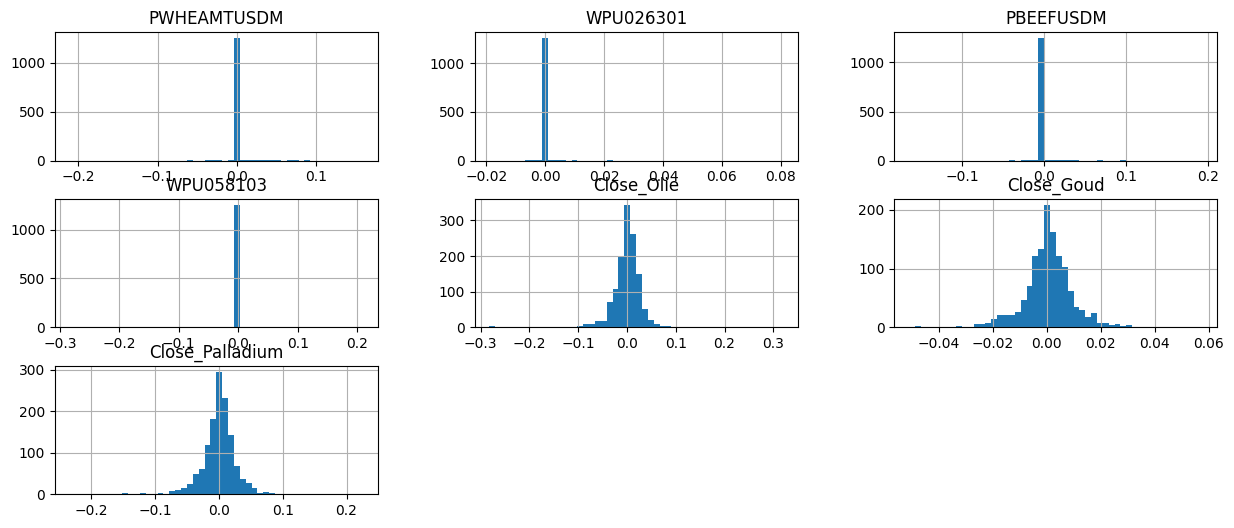

In [29]:
log_returns.hist(bins=50, figsize=(15,6))

# Statistische analyse
Als eerste gaan we nu testen of de dagrendementen van onze aandelen, crypto's en obligaties in onze portfolio wel ' normaal'  verdeeld zijn. Daarvoor gebruiken we 2 functies: 

In [30]:
def print_statistics(array):
  sta = scs.describe(array)
  print("%14s %15s" % ("statistic", "value"))
  print(30* "-")
  print("%14s %15.5f" % ("size",sta[0]))
  print("%14s %15.5f" % ("min",sta[1][0]))
  print("%14s %15.5f" % ("max",sta[1][1]))
  print("%14s %15.5f" % ("mean",sta[2]))
  print("%14s %15.5f" % ("std",np.sqrt(sta[3])))
  print("%14s %15.5f" % ("skew",sta[4]))
  print("%14s %15.5f" % ("kurtosis",sta[5]))

def normality_tests(arr):
  print("Skew of data set %14.3f" % scs.skew(arr))
  print("Skew test p-value %14.3f" % scs.skewtest(arr)[1])
  print("Kurt of data set %14.3f" % scs.kurtosis(arr))
  print("Kurt test p-value %14.3f" % scs.kurtosistest(arr)[1])
  print("Norm test p-value %14.3f" % scs.normaltest(arr)[1])

Als we deze 2 functies toepassen op onze portfolio, levert dat het volgende resultaat op. We beginnen met de ' statistics':

In [31]:
symbols = ["PWHEAMTUSDM", "WPU026301","PBEEFUSDM","WPU058103","Close_Olie","Close_Goud","Close_Palladium"]
noa = len(symbols)

In [32]:
for sym in symbols:
  print("\nResults for symbol %s" % sym)
  print(30 * "-")
  log_data = np.array(log_returns[sym].dropna())
  print_statistics(log_data)


Results for symbol PWHEAMTUSDM
------------------------------
     statistic           value
------------------------------
          size      1302.00000
           min        -0.21110
           max         0.15869
          mean         0.00037
           std         0.01475
          skew        -0.56832
      kurtosis        77.02268

Results for symbol WPU026301
------------------------------
     statistic           value
------------------------------
          size      1302.00000
           min        -0.01901
           max         0.08070
          mean         0.00018
           std         0.00289
          skew        19.10659
      kurtosis       490.94154

Results for symbol PBEEFUSDM
------------------------------
     statistic           value
------------------------------
          size      1302.00000
           min        -0.16479
           max         0.19388
          mean         0.00021
           std         0.01064
          skew         3.03536
      kur

Conclusie?<br>

Is **negative skewness** good?<br>
A negative skew is generally not good, because it highlights the risk of left tail events or what are sometimes referred to as “[black swan events](https://en.wikipedia.org/wiki/Black_swan_theory).” While a consistent and steady track record with a positive mean would be a great thing, if the track record has a negative skew then you should proceed with caution.

What does it mean if **kurtosis** is above 3?<br>
If the kurtosis is greater than 3, then the dataset has heavier tails than a normal distribution (more in the tails). If the kurtosis is less than 3, then the dataset has lighter tails than a normal distribution (less in the tails).

En nu de 'normaliteitstest':

In [33]:
for sym in symbols:
  print("\nResults for symbol %s" % sym)
  print(32 * "-")
  log_data = np.array(log_returns[sym].dropna())
  normality_tests(log_data)


Results for symbol PWHEAMTUSDM
--------------------------------
Skew of data set         -0.568
Skew test p-value          0.000
Kurt of data set         77.023
Kurt test p-value          0.000
Norm test p-value          0.000

Results for symbol WPU026301
--------------------------------
Skew of data set         19.107
Skew test p-value          0.000
Kurt of data set        490.942
Kurt test p-value          0.000
Norm test p-value          0.000

Results for symbol PBEEFUSDM
--------------------------------
Skew of data set          3.035
Skew test p-value          0.000
Kurt of data set        151.292
Kurt test p-value          0.000
Norm test p-value          0.000

Results for symbol WPU058103
--------------------------------
Skew of data set         -1.820
Skew test p-value          0.000
Kurt of data set        100.873
Kurt test p-value          0.000
Norm test p-value          0.000

Results for symbol Close_Olie
--------------------------------
Skew of data set          0.06

Conclusie?<br>
Alle p-waarden zijn kleiner dan 0,05, dus we verwerpen de nulhypothese dat de dagrendementen normaal verdeeld zijn.

We kunnen er ook nog mooie plaatjes van maken:

Text(0, 0.5, 'sample quantiles')

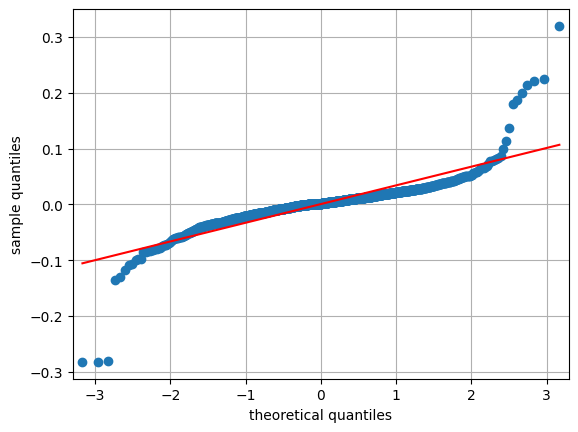

In [34]:
sm.qqplot(log_returns['Close_Olie'].dropna(), line='s')
plt.grid(True)
plt.xlabel('theoretical quantiles')
plt.ylabel('sample quantiles')

En de plaatje(s) onderschrijven de eerdere conclusies:<br> de dagrendementen van de financiele waarden in onze portfolio zijn NIET normaal verdeeld: het staartrisico aan de linkerkant (= verlieszijde!) & aan de rechterkant (= winstzijde!) is te groot.

# Portfolio-optimalisatie
We gaan op basis van gewichten onze portfolio optimaliseren. We maken een nieuwe variabele aan ' rets' die gelijk is aan de log_returns van de statistische analyse. Verder maken we een variabele aan voor de [risicovrije rente](https://en.wikipedia.org/wiki/Risk-free_rate) (rf).

In [35]:
rets = log_returns
rf = 0.02 # risicovrije rente van 2%

We maken een 'random' gewichtsverdeling voor onze portfolio:

In [36]:
weights = np.random.random(noa)
weights /= np.sum(weights)
weights.round(2)

array([0.24, 0.19, 0.04, 0.1 , 0.06, 0.14, 0.23])

Vervolgens berekenen we op basis van deze gewichten voor onze portfolio:<br>
- het verwachte rendement<br>
- de variantie<br>
- de standaardafwijking<br>
- de [Sharpe-ratio](https://en.wikipedia.org/wiki/Sharpe_ratio)

In [37]:
epr = np.sum(rets.mean() * weights)*252 # expected portfolio return
print("The expected portfolio return is", epr.round(2))

epv = np.dot(weights.T, np.dot(rets.cov()*252, weights)) # expected portfolio variance
print("The expected portfolio variance is", epv.round(2))

eps = epv**0.5 # expected portfolio standard deviation
print("The expected portfolio standard deviation is", eps.round(2))

sharpe = (epr-rf)/eps # Sharpe ratio
print("The expected sharpe ratio is", sharpe.round(2))

The expected portfolio return is 0.09
The expected portfolio variance is 0.02
The expected portfolio standard deviation is 0.14
The expected sharpe ratio is 0.5


# Monte Carlo-simulatie
Met behulp van een Monte Carlo-simulatie maken we 2.500 portfolio's met verschillende gewichten.

In [38]:
# Monte Carlo simulatie van alle mogelijke portfolio's:
prets = []
pvols = []

for p in range(2500):
  weights = np.random.random(noa)
  weights /= np.sum(weights)
  prets.append(np.sum(rets.mean() * weights)*252)
  pvols.append(np.sqrt(np.dot(weights.T, np.dot(rets.cov()*252, weights))))
  
prets = np.array(prets)
pvols = np.array(pvols)

In de grafiek zie je het resultaat van de simulatie, waarbij op de x-as de verwachte variantie = volatiliteit staat en op de y-as het verwachte rendement.

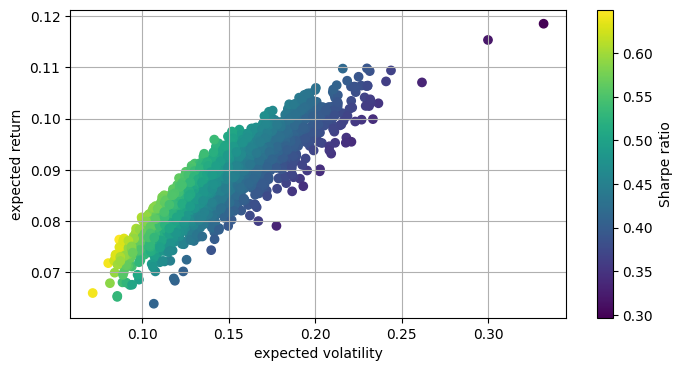

In [39]:
plt.figure(figsize=(8,4))
plt.scatter(pvols,prets, c=(prets-rf)/pvols, marker='o')
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')

# Optimalisatie
Om te optimaliseren hebben we wat nieuwe functies nodig:

In [40]:
from pyparsing.helpers import OpAssoc
import scipy.optimize as sco

We maken 3 functies aan:<br>
- een functie ('statistics') die het rendement, risco en de Sharpe-ratio van de portfolio's berekent<br>
- een functie ('min_variance') die de gewichten berekent voor een portfolio met minimaal risico<br>
- een functie ('min_sharpe') die de gewichten berekent voor een portfolio met een MAXIMALE Sharpe-ratio

In [41]:
def statistics(weights):
  weights = np.array(weights)
  pret = np.sum(rets.mean() * weights)*252
  pvol = np.sqrt(np.dot(weights.T, np.dot(rets.cov()*252, weights)))
  return np.array([pret, pvol, (pret-rf)/pvol])

def min_func_variance(weights):
  return statistics(weights)[1]**2

def min_func_sharpe(weights):
  return -statistics(weights)[2]

Vervolgens laten we het algoritme ('[SLSQP](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html)') de optimale gewichten berekenen:

In [42]:
cons = ({'type':'eq', 'fun': lambda x: np.sum(x)-1 })
bnds = tuple((0,1) for x in range(noa))

opts = sco.minimize(min_func_sharpe, noa * [1./noa,], method='SLSQP', bounds=bnds, constraints=cons)
optv = sco.minimize(min_func_variance, noa * [1./noa,], method='SLSQP', bounds=bnds, constraints=cons)

Optimale gewichten voor maximale Sharpe-ratio:

In [43]:
print(opts['x'].round(2)) # optimale gewichten voor maximale Sharpe-ratio
print(statistics(opts['x']).round(2)) # het rendement, de standaardafwijking en de Sharpe-ratio van de portefeuille met max Sharpe

[0.06 0.68 0.06 0.02 0.02 0.15 0.01]
[0.06 0.05 0.77]


Optimale gewichten voor minimale variantie = minimaal risico:

In [44]:
print(optv['x'].round(2)) # optimale gewichten voor minimal variance
print(statistics(optv['x']).round(2)) # het rendement, de standaardafwijking en de Sharpe-ratio van de portefeuille met min variance

[0.01 0.85 0.07 0.   0.   0.07 0.  ]
[0.05 0.04 0.68]


# De Grenslijn met de optimale portfolio's
We gaan de grafiek nog wat mooier maken door er de [efficiente grenslijn](https://en.wikipedia.org/wiki/Efficient_frontier) aan toe te voegen, bedacht door [Harry Markowitz](https://en.wikipedia.org/wiki/Harry_Markowitz).

We starten bij de portfolio met het minste risico, en van daar af bouwen we de lijn op:

In [45]:
def min_func_port(weights):
  return statistics(weights)[1]

cons = ({'type':'eq', 'fun': lambda x: statistics(x)[0]-tret },{'type':'eq', 'fun': lambda x: np.sum(x)-1})
bnds = tuple((0,1) for x in weights)

trets = np.linspace(0.0,0.25,50)
tvols = []

for tret in trets:
  cons = ({'type':'eq', 'fun': lambda x: statistics(x)[0]-tret },{'type':'eq', 'fun': lambda x: np.sum(x)-1})
  res = sco.minimize(min_func_port, noa * [1./noa,], method='SLSQP', bounds=bnds, constraints=cons)
  tvols.append(res['fun'])

Alles is berekend, tijd voor de grafiek:

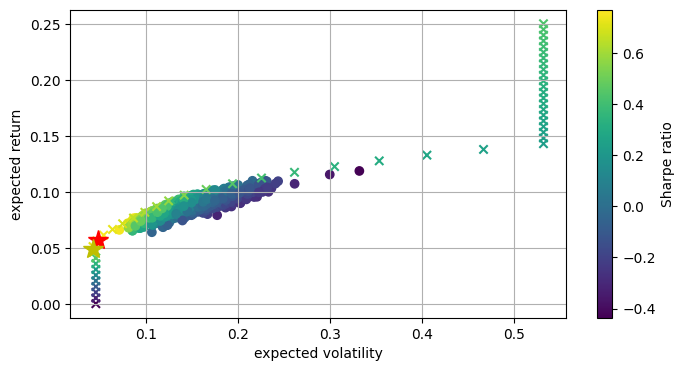

In [46]:
plt.figure(figsize=(8,4))
plt.scatter(pvols,prets, c=(prets-rf)/pvols, marker='o') # random portfolio's
plt.scatter(tvols,trets, c=(trets-rf)/tvols, marker='x') # efficient portfolio's
plt.plot(statistics(opts['x'])[1],statistics(opts['x'])[0], 'r*',markersize=15.0 ) # portfolio met max Sharpe
plt.plot(statistics(optv['x'])[1],statistics(optv['x'])[0], 'y*',markersize=15.0 ) # portfolio met min variance
plt.grid(True)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')



# De Security Market-lijn met de marktportfolio
Tot slot vervolmaken we de grafiek door er de [Security Market Line](https://en.wikipedia.org/wiki/Security_market_line) aan toe te voegen: alle portfolio's op deze lijn zijn optimaal (en samen te stellen door te lenen of te sparen), het hangt van je eigen risicovoorkeur af welke je kiest. 

We lezen eerst wat extra functies in:

In [47]:
import scipy.interpolate as sci
from pyparsing.helpers import OpAssoc
import scipy.optimize as sco

Vervolgens gebruiken we drie functies om de lijn te berekenen:

In [48]:
ind = np.argmin(tvols)
evols = tvols[ind:]
erets = trets[ind:]

tck = sci.splrep(evols, erets)

def f(x):
  return sci.splev(x, tck, der=0)

def df(x):
  return sci.splev(x, tck, der=1)

def equations(p, rf=0.01):
  eq1 = rf - p[0]
  eq2 = rf + p[1] * p[2] -f(p[2])
  eq3 = p[1] - df(p[2])
  return eq1, eq2, eq3

opt = sco.fsolve(equations, [0.01,0.2,0.2])

np.round(equations(opt),6)

cons = ({'type':'eq', 'fun': lambda x: statistics(x)[0]-f(opt[2]) },{'type':'eq', 'fun': lambda x: np.sum(x)-1})
res = sco.minimize(min_func_port, noa * [1./noa,], method='SLSQP', bounds=bnds, constraints=cons)

ValueError: ignored

Alles berekend, tijd voor de laatste grafiek:

NameError: ignored

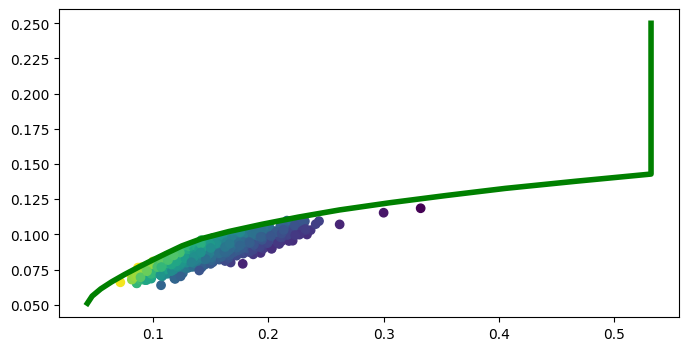

In [49]:
plt.figure(figsize=(8,4))
plt.scatter(pvols,prets, c=(prets-rf)/pvols, marker='o') # random portfolio's
plt.plot(evols, erets,'g', lw=4.0 ) # efficient frontier
cx = np.linspace(0.0, 0.3)
plt.plot(cx, opt[0] + opt[1] * cx, lw=1.5) # capital market line
plt.plot(opt[2], f(opt[2]), 'r*', markersize=15.0)  # marktportfolio
plt.grid(True)
plt.axhline(0, color='k', ls='--', lw=2.0)
plt.axvline(0, color='k', ls='--', lw=2.0)
plt.xlabel('expected volatility')
plt.ylabel('expected return')
plt.colorbar(label='Sharpe ratio')

De rode ster geeft de portfolio aan met de maximale Sharpe-ratio. Deze portfolio noemen we ook wel de marktportfolio. Om deze portfolio samen te stellen met behulp van onze portfolio, zou je de volgende gewichten moeten gebruiken:

In [50]:
print(res['x'].round(2)) # gewichten van de marktportfolio

[0. 0. 0. 0. 1. 0. 0.]


De marktportfolio heeft onderstaand(e) rendement, standaardafwijking en Sharpe-ratio:

In [51]:
print(statistics(res['x']).round(2)) # rendement, standaardafwijking en sharpe-ratio van de marktportfolio

[0.14 0.53 0.23]


NB: de 'echte' (wereld)marktportfolio zou een samenstelling van alle beschikbare financiele producten ter wereld moeten zijn, dat is practisch niet helemaal haalbaar ..<br>

Je bent dus nooit helemaal ' optimaal' gespreid, er blijft altijd een landen / sector / valuta / etc risico over.